In [ ]:

import pandas as pd

sales = pd.read_csv("duka_sales.csv")

print("Dataset loaded successfully!")
print("Number of rows and columns:", sales.shape)

print("\nColumn names:")
print(sales.columns.tolist())

print("\nFirst five rows:")
display(sales.head())

print("\nDataset information:")
sales.info()

Dataset loaded successfully!
Number of rows and columns: (1000, 7)

Column names:
['order_id', 'order_date', 'branch', 'product', 'quantity', 'channel', 'unit_price']

First five rows:


,order_id,order_date,branch,product,quantity,channel,unit_price
0,1001,2026-06-03,Nakuru,Phone,3,In-store,15000
1,1002,2026-02-02,Nairobi,Laptop,4,In-store,65000
2,1003,2026-01-05,Nakuru,Tablet,5,In-store,28000
3,1004,2026-04-26,Nairobi,Headphones,5,In-store,2500
4,1005,2026-03-07,Nairobi,Headphones,3,In-store,2500



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   order_id    1000 non-null   int64 
 1   order_date  1000 non-null   object
 2   branch      1000 non-null   object
 3   product     1000 non-null   object
 4   quantity    1000 non-null   int64 
 5   channel     1000 non-null   object
 6   unit_price  1000 non-null   int64 
dtypes: int64(3), object(4)
memory usage: 54.8+ KB


# Duka Electronics H1 2026 Board Report

## Audience

The Duka Electronics CEO and board members, who are non-technical and need a clear summary of sales performance for January–June 2026.

## Decision

The board must decide how to allocate the marketing budget and which branches or products need more attention in the second half of 2026.

## Big Idea

The board should use first-half sales performance to identify the strongest revenue contributors and areas of declining momentum, then target second-half marketing investment where the evidence indicates the greatest opportunity.

## Situation–Complication–Resolution (SCR)

**Situation:** Duka Electronics has sales data for the first half of 2026 that can show how revenue varies by month, branch, product and sales channel.

**Complication:** Overall totals alone may hide monthly changes, differences between branches and products, and variations in individual order values.

**Resolution:** Review a concise set of charts showing revenue trends, branch and product performance, order-value distribution and channel contributions, then use these findings to guide second-half marketing decisions.


In [ ]:

# Step 5: Prepare and inspect the sales data

# Convert order_date into a proper date format
sales["order_date"] = pd.to_datetime(sales["order_date"], errors="coerce")

# Ensure sales quantities and prices are numeric
sales["quantity"] = pd.to_numeric(sales["quantity"], errors="coerce")
sales["unit_price"] = pd.to_numeric(sales["unit_price"], errors="coerce")

# Calculate revenue for each order record
sales["revenue"] = sales["quantity"] * sales["unit_price"]

# Inspect data quality
print("Dataset shape:", sales.shape)
print("\nMissing values:")
print(sales.isnull().sum())

print("\nDuplicate rows:", sales.duplicated().sum())

print("\nDate range:")
print("First date:", sales["order_date"].min())
print("Last date:", sales["order_date"].max())

print("\nTotal revenue: KES {:,.2f}".format(sales["revenue"].sum()))

print("\nRevenue by branch:")
display(
    sales.groupby("branch")["revenue"]
    .sum()
    .sort_values(ascending=False)
    .to_frame()
)

print("\nRevenue by product:")
display(
    sales.groupby("product")["revenue"]
    .sum()
    .sort_values(ascending=False)
    .to_frame()
)

Dataset shape: (1000, 8)

Missing values:
order_id      0
order_date    0
branch        0
product       0
quantity      0
channel       0
unit_price    0
revenue       0
dtype: int64

Duplicate rows: 0

Date range:
First date: 2026-01-01 00:00:00
Last date: 2026-06-29 00:00:00

Total revenue: KES 71,792,500.00

Revenue by branch:


,revenue
branch,
Nairobi,26106100
Mombasa,14003700
Nakuru,11970400
Kisumu,10868100
Eldoret,8844200



Revenue by product:


,revenue
product,
Laptop,41535000
Tablet,19348000
Phone,8880000
Headphones,1387500
Charger,642000


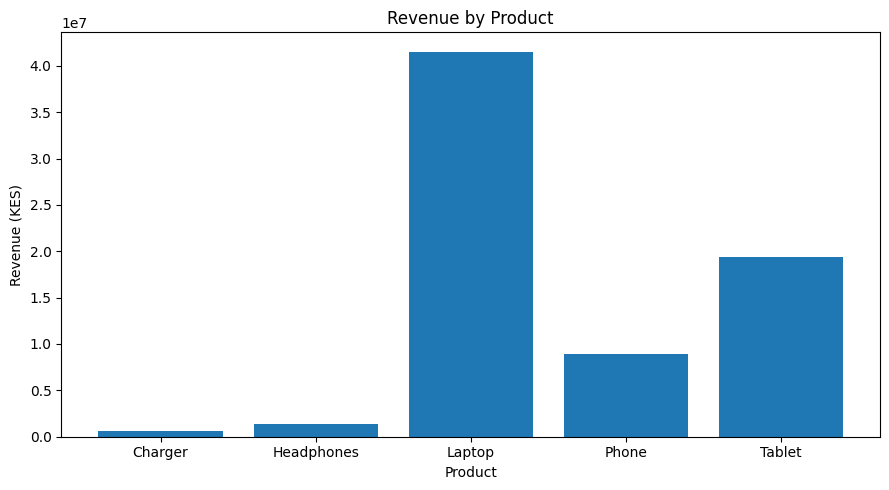

In [ ]:

import matplotlib.pyplot as plt

# Calculate total revenue for each product
product_revenue = sales.groupby("product")["revenue"].sum()

# Create a basic chart
fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(product_revenue.index, product_revenue.values)

ax.set_title("Revenue by Product")
ax.set_xlabel("Product")
ax.set_ylabel("Revenue (KES)")

plt.tight_layout()
plt.savefig("before.png", dpi=150, bbox_inches="tight")
plt.show()

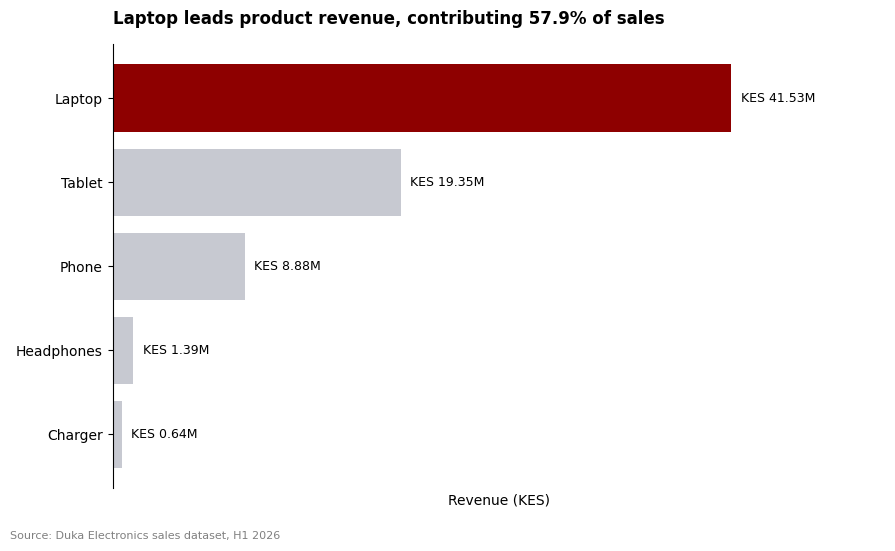

In [ ]:

# Step 7: Professional product revenue chart

# Sort products from lowest to highest for a horizontal bar chart
product_revenue = sales.groupby("product")["revenue"].sum().sort_values()

# Identify the top-performing product
top_product = product_revenue.idxmax()
total_revenue = product_revenue.sum()
top_share = product_revenue.max() / total_revenue * 100

# Highlight only the top product
colors = [
    "#8E0000" if product == top_product else "#C7C9D1"
    for product in product_revenue.index
]

fig, ax = plt.subplots(figsize=(9, 5.5))

bars = ax.barh(
    product_revenue.index,
    product_revenue.values,
    color=colors
)

# Add direct value labels
for bar, value in zip(bars, product_revenue.values):
    ax.text(
        value + product_revenue.max() * 0.015,
        bar.get_y() + bar.get_height() / 2,
        f"KES {value / 1_000_000:.2f}M",
        va="center",
        fontsize=9
    )

# Create an insight title using the actual results
ax.set_title(
    f"{top_product} leads product revenue, contributing {top_share:.1f}% of sales",
    loc="left",
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Revenue (KES)")
ax.set_ylabel("")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["bottom"].set_visible(False)
ax.set_xticks([])
ax.set_xlim(0, product_revenue.max() * 1.25)

fig.text(
    0.01, 0.01,
    "Source: Duka Electronics sales dataset, H1 2026",
    fontsize=8,
    color="grey"
)

plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.savefig("after.png", dpi=150, bbox_inches="tight")
plt.show()

Charts saved successfully!

Before chart:


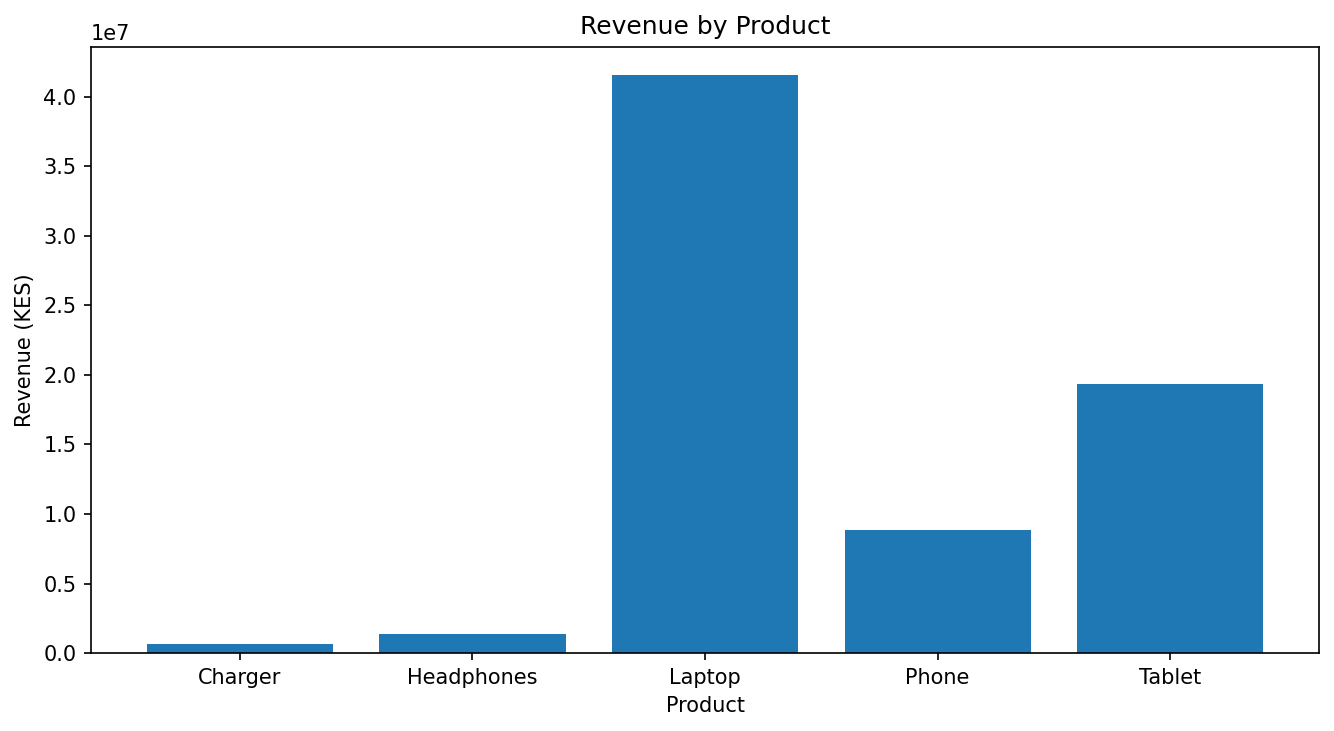


After chart:


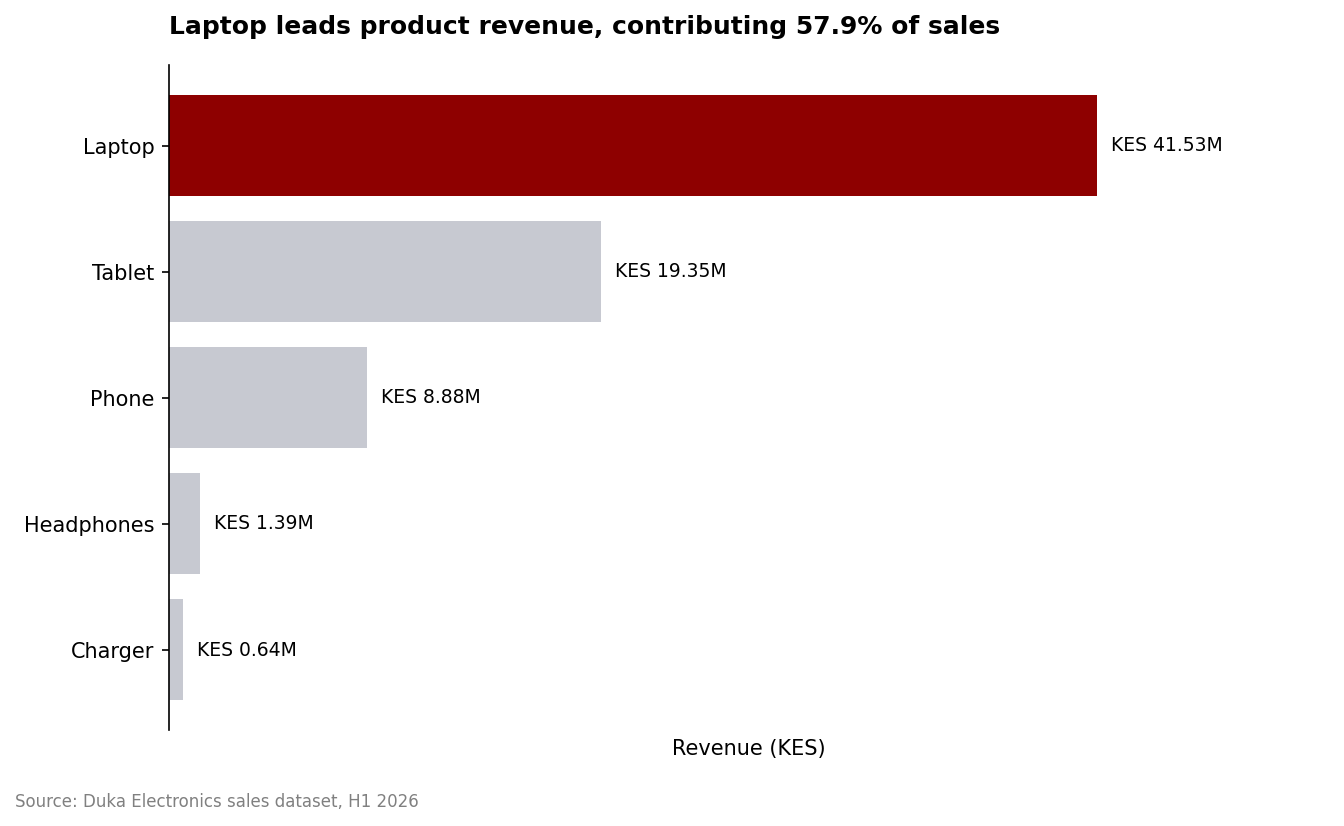

In [ ]:

import os
import shutil
from IPython.display import display, Image

# Create the required figures folder
os.makedirs("figures", exist_ok=True)

# Copy both chart images into the folder
shutil.copy("before.png", "figures/before.png")
shutil.copy("after.png", "figures/after.png")

print("Charts saved successfully!")

print("\nBefore chart:")
display(Image(filename="figures/before.png"))

print("\nAfter chart:")
display(Image(filename="figures/after.png"))

## Before-and-After Design Comparison

* **Sorting:** The improved chart sorts products by revenue, making comparisons easier.
* **Orientation:** Horizontal bars make product names easier to read.
* **Colour:** Grey bars provide context, while PLP redberry highlights the highest-revenue product.
* **Direct labels:** Revenue values are displayed on the bars so readers can compare results quickly.
* **Insight title:** The title identifies the leading product and its share of total revenue.
* **Decluttering:** Unnecessary borders and x-axis tick marks are removed to keep attention on the findings.
* **Source line:** The chart identifies the dataset and reporting period.


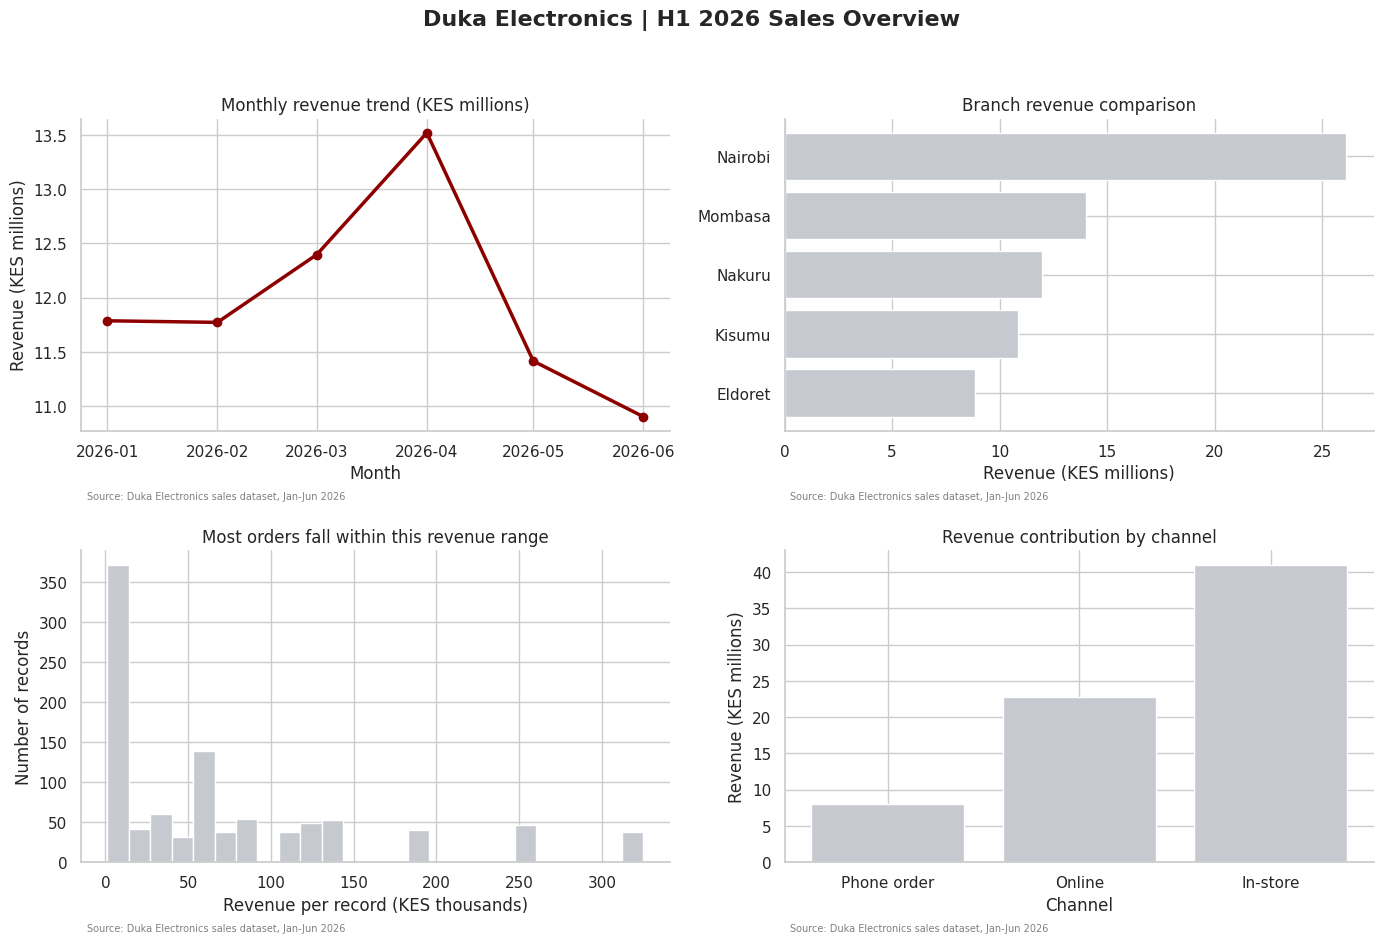

H1 2026 records: 1000
H1 2026 revenue: KES 71,792,500.00


In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Prepare a consistent visual style
sns.set_theme(style="whitegrid")

# Use the first half of 2026 for the board report
h1_sales = sales[
    (sales["order_date"] >= "2026-01-01") &
    (sales["order_date"] < "2026-07-01")
].copy()

if h1_sales.empty:
    print("No sales records found for January-June 2026.")
    print("Check the date range printed in Step 5.")
else:
    # Aggregate the data before plotting
    monthly_revenue = (
        h1_sales.set_index("order_date")["revenue"]
        .resample("MS").sum()
    )

    branch_revenue = (
        h1_sales.groupby("branch")["revenue"]
        .sum().sort_values()
    )

    channel_revenue = (
        h1_sales.groupby("channel")["revenue"]
        .sum().sort_values()
    )

    fig, axes = plt.subplots(2, 2, figsize=(14, 10))

    # Chart 1: Monthly revenue trend
    axes[0, 0].plot(
        monthly_revenue.index,
        monthly_revenue.values / 1e6,
        marker="o", color="#8E0000", linewidth=2.5
    )
    axes[0, 0].set_title("Monthly revenue trend (KES millions)")
    axes[0, 0].set_ylabel("Revenue (KES millions)")
    axes[0, 0].set_xlabel("Month")

    # Chart 2: Revenue by branch
    axes[0, 1].barh(
        branch_revenue.index,
        branch_revenue.values / 1e6,
        color="#C7C9D1"
    )
    axes[0, 1].set_title("Branch revenue comparison")
    axes[0, 1].set_xlabel("Revenue (KES millions)")

    # Chart 3: Distribution of order revenue
    axes[1, 0].hist(
        h1_sales["revenue"].dropna() / 1000,
        bins=25, color="#C7C9D1", edgecolor="white"
    )
    axes[1, 0].set_title("Most orders fall within this revenue range")
    axes[1, 0].set_xlabel("Revenue per record (KES thousands)")
    axes[1, 0].set_ylabel("Number of records")

    # Chart 4: Revenue by channel
    axes[1, 1].bar(
        channel_revenue.index,
        channel_revenue.values / 1e6,
        color="#C7C9D1"
    )
    axes[1, 1].set_title("Revenue contribution by channel")
    axes[1, 1].set_ylabel("Revenue (KES millions)")
    axes[1, 1].set_xlabel("Channel")

    # Add a source line to each panel
    for ax in axes.flat:
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.text(
            0.01, -0.22,
            "Source: Duka Electronics sales dataset, Jan-Jun 2026",
            transform=ax.transAxes,
            fontsize=7, color="grey"
        )

    fig.suptitle(
        "Duka Electronics | H1 2026 Sales Overview",
        fontsize=16, fontweight="bold"
    )

    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.savefig("sales_overview.png", dpi=200, bbox_inches="tight")
    plt.show()

    print("H1 2026 records:", len(h1_sales))
    print("H1 2026 revenue: KES {:,.2f}".format(
        h1_sales["revenue"].sum()
    ))

Board report image saved:
reports/duka_board_report.png


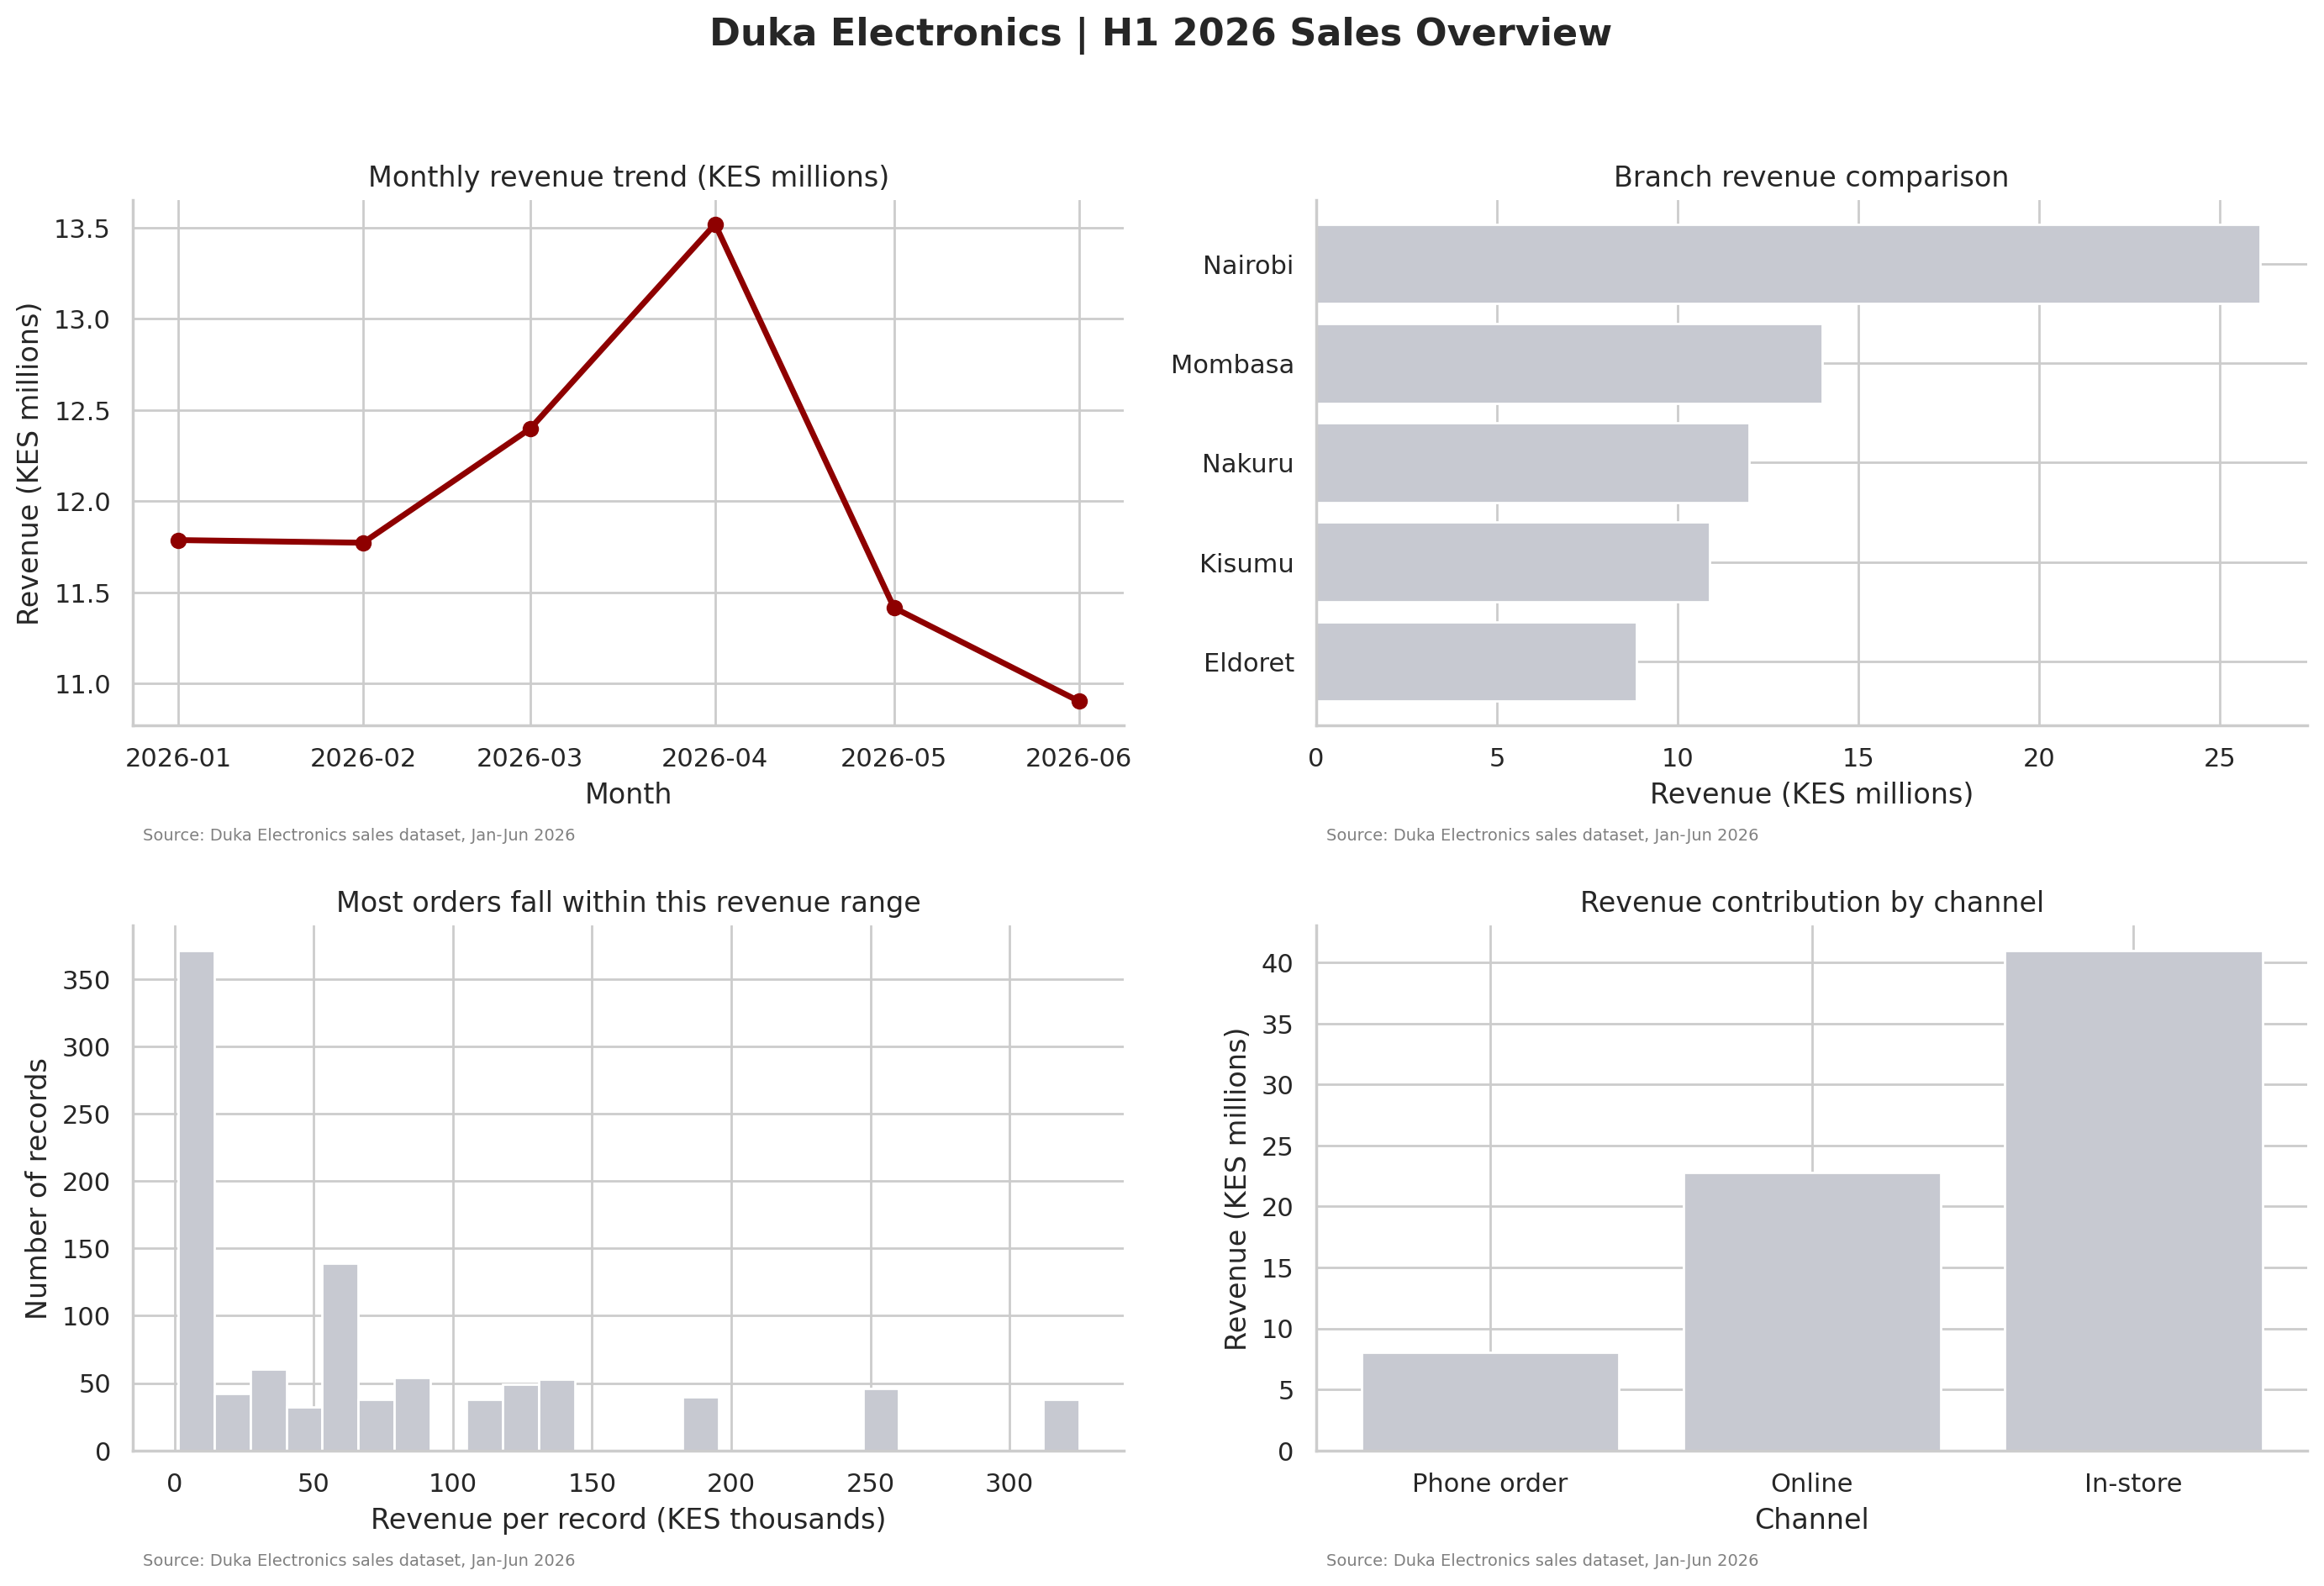

In [ ]:

import os
import shutil
from IPython.display import display, Image

# Create the required report folder
os.makedirs("reports", exist_ok=True)

# Save a copy of the four-panel overview
shutil.copy(
    "sales_overview.png",
    "reports/duka_board_report.png"
)

print("Board report image saved:")
print("reports/duka_board_report.png")

display(Image(filename="reports/duka_board_report.png"))

In [ ]:

# Key H1 2026 findings

print("TOTAL H1 REVENUE")
print(f"KES {h1_sales['revenue'].sum():,.2f}")

print("\nMONTHLY REVENUE")
monthly_summary = (
    h1_sales.groupby(h1_sales["order_date"].dt.to_period("M"))["revenue"]
    .sum()
    .sort_values(ascending=False)
)
display(monthly_summary.to_frame("Revenue (KES)"))

print("\nTOP BRANCH")
branch_summary = (
    h1_sales.groupby("branch")["revenue"]
    .sum()
    .sort_values(ascending=False)
)
display(branch_summary.to_frame("Revenue (KES)"))

print("\nTOP PRODUCT")
product_summary = (
    h1_sales.groupby("product")["revenue"]
    .sum()
    .sort_values(ascending=False)
)
display(product_summary.to_frame("Revenue (KES)"))

print("\nREVENUE BY CHANNEL")
channel_summary = (
    h1_sales.groupby("channel")["revenue"]
    .sum()
    .sort_values(ascending=False)
)
display(channel_summary.to_frame("Revenue (KES)"))

TOTAL H1 REVENUE
KES 71,792,500.00

MONTHLY REVENUE


,Revenue (KES)
order_date,
2026-04,13518300
2026-03,12396800
2026-01,11786600
2026-02,11772000
2026-05,11415400
2026-06,10903400



TOP BRANCH


,Revenue (KES)
branch,
Nairobi,26106100
Mombasa,14003700
Nakuru,11970400
Kisumu,10868100
Eldoret,8844200



TOP PRODUCT


,Revenue (KES)
product,
Laptop,41535000
Tablet,19348000
Phone,8880000
Headphones,1387500
Charger,642000



REVENUE BY CHANNEL


,Revenue (KES)
channel,
In-store,40969200
Online,22786100
Phone order,8037200


## Key Findings — H1 2026

1. **Total revenue:** Duka Electronics generated KES 71.79 million in revenue during the first half of 2026.
2. **Monthly performance:** April recorded the highest monthly revenue at KES 13.52 million, while June recorded the lowest at KES 10.90 million.
3. **Branch performance:** Nairobi led all branches with KES 26.11 million, while Eldoret recorded KES 8.84 million.
4. **Product performance:** Laptops generated KES 41.54 million, making them the leading product by revenue. Chargers generated the least, at KES 642,000.
5. **Sales channels:** In-store sales contributed KES 40.97 million, followed by online sales at KES 22.79 million and phone orders at KES 8.04 million.

### Initial H2 Recommendation

Maintain support for strong-performing laptop sales and Nairobi operations while investigating the reasons for lower revenue in Eldoret and the decline in monthly revenue after April. Test targeted marketing campaigns for online and phone-order sales, then monitor results before reallocating the full H2 budget.


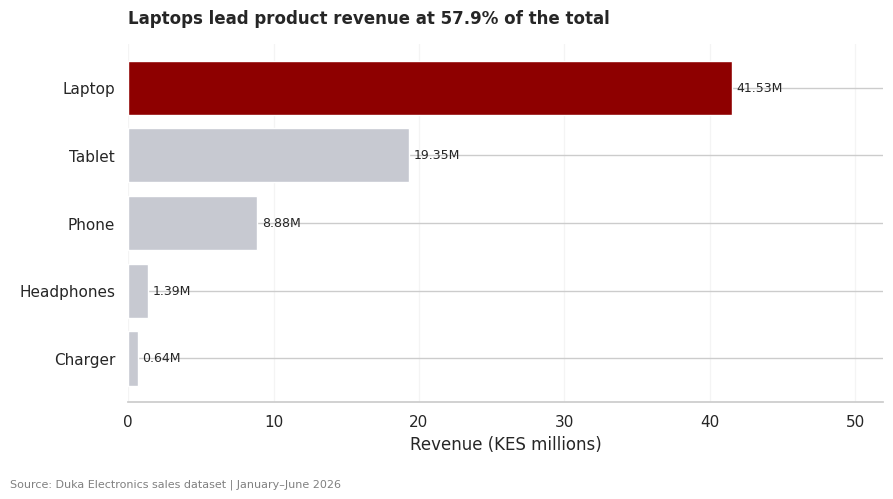

Top product: Laptop
Share of product revenue: 57.9%


In [ ]:

# Final product revenue chart for the board report

import matplotlib.pyplot as plt

product_revenue = (
    h1_sales.groupby("product")["revenue"]
    .sum()
    .sort_values()
)

top_product = product_revenue.idxmax()
total_revenue = product_revenue.sum()
top_share = product_revenue.max() / total_revenue * 100

colors = [
    "#8E0000" if product == top_product else "#C7C9D1"
    for product in product_revenue.index
]

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.barh(
    product_revenue.index,
    product_revenue.values / 1_000_000,
    color=colors
)

for bar, value in zip(bars, product_revenue.values):
    ax.text(
        bar.get_width() + 0.3,
        bar.get_y() + bar.get_height() / 2,
        f"{value / 1_000_000:.2f}M",
        va="center",
        fontsize=9
    )

ax.set_title(
    f"Laptops lead product revenue at {top_share:.1f}% of the total",
    loc="left",
    fontweight="bold",
    pad=15
)
ax.set_xlabel("Revenue (KES millions)")
ax.set_ylabel("")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)
ax.set_xlim(0, product_revenue.max() / 1_000_000 * 1.25)

fig.text(
    0.01, 0.01,
    "Source: Duka Electronics sales dataset | January–June 2026",
    fontsize=8, color="grey"
)

plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.savefig("figures/product_revenue.png", dpi=200, bbox_inches="tight")
plt.show()

print(f"Top product: {top_product}")
print(f"Share of product revenue: {top_share:.1f}%")

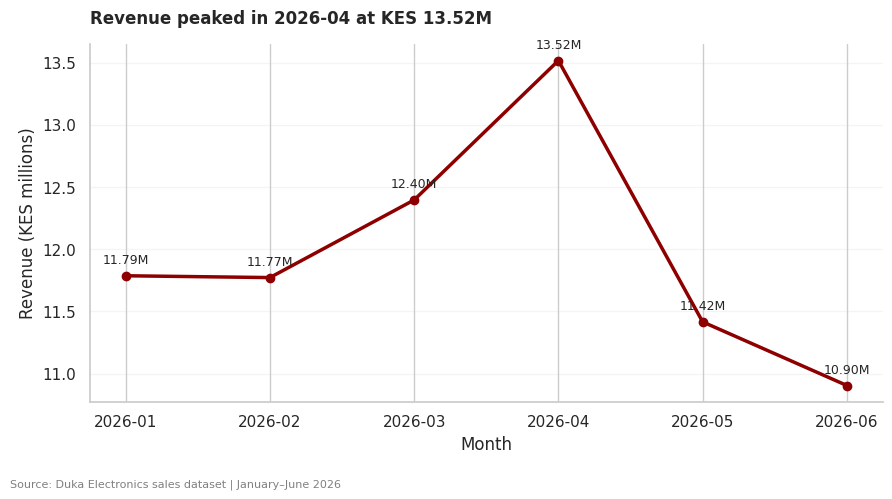

Highest month: 2026-04 — KES 13.52 million
Lowest month: 2026-06 — KES 10.90 million


In [ ]:

# Monthly revenue trend for the board report

import matplotlib.pyplot as plt

monthly_revenue = (
    h1_sales.groupby(h1_sales["order_date"].dt.to_period("M"))["revenue"]
    .sum()
    .sort_index()
)

monthly_revenue.index = monthly_revenue.index.astype(str)
monthly_millions = monthly_revenue / 1_000_000

best_month = monthly_millions.idxmax()
best_value = monthly_millions.max()
lowest_month = monthly_millions.idxmin()
lowest_value = monthly_millions.min()

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    monthly_millions.index,
    monthly_millions.values,
    marker="o",
    linewidth=2.5,
    color="#8E0000"
)

for month, value in zip(monthly_millions.index, monthly_millions.values):
    ax.annotate(
        f"{value:.2f}M",
        (month, value),
        xytext=(0, 9),
        textcoords="offset points",
        ha="center",
        fontsize=9
    )

ax.set_title(
    f"Revenue peaked in {best_month} at KES {best_value:.2f}M",
    loc="left",
    fontweight="bold",
    pad=15
)
ax.set_xlabel("Month")
ax.set_ylabel("Revenue (KES millions)")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

fig.text(
    0.01, 0.01,
    "Source: Duka Electronics sales dataset | January–June 2026",
    fontsize=8,
    color="grey"
)

plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.savefig("figures/monthly_revenue.png", dpi=200, bbox_inches="tight")
plt.show()

print(f"Highest month: {best_month} — KES {best_value:.2f} million")
print(f"Lowest month: {lowest_month} — KES {lowest_value:.2f} million")

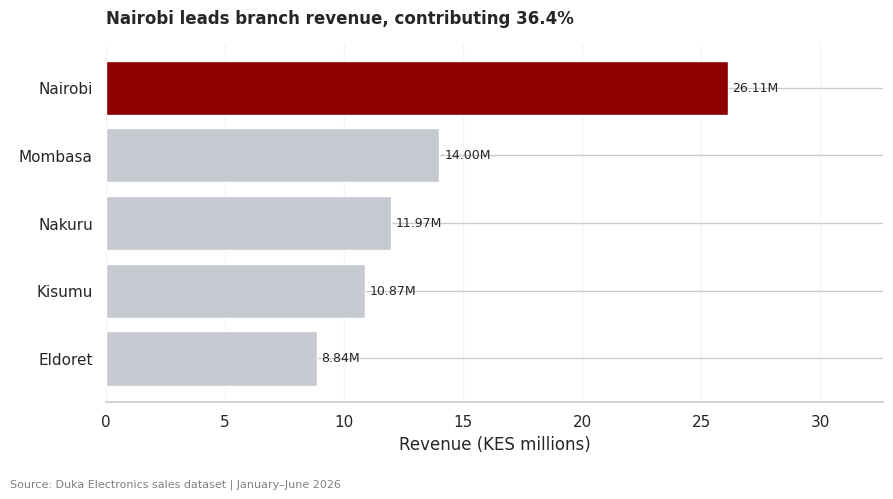

Top branch: Nairobi
Share of branch revenue: 36.4%


In [ ]:

# Branch revenue comparison for the board report

import matplotlib.pyplot as plt

branch_revenue = (
    h1_sales.groupby("branch")["revenue"]
    .sum()
    .sort_values()
)

top_branch = branch_revenue.idxmax()
top_branch_share = branch_revenue.max() / branch_revenue.sum() * 100

colors = [
    "#8E0000" if branch == top_branch else "#C7C9D1"
    for branch in branch_revenue.index
]

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.barh(
    branch_revenue.index,
    branch_revenue.values / 1_000_000,
    color=colors
)

for bar, value in zip(bars, branch_revenue.values):
    ax.text(
        bar.get_width() + 0.2,
        bar.get_y() + bar.get_height() / 2,
        f"{value / 1_000_000:.2f}M",
        va="center",
        fontsize=9
    )

ax.set_title(
    f"{top_branch} leads branch revenue, contributing {top_branch_share:.1f}%",
    loc="left",
    fontweight="bold",
    pad=15
)
ax.set_xlabel("Revenue (KES millions)")
ax.set_ylabel("")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)
ax.set_xlim(0, branch_revenue.max() / 1_000_000 * 1.25)

fig.text(
    0.01, 0.01,
    "Source: Duka Electronics sales dataset | January–June 2026",
    fontsize=8,
    color="grey"
)

plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.savefig("figures/branch_revenue.png", dpi=200, bbox_inches="tight")
plt.show()

print(f"Top branch: {top_branch}")
print(f"Share of branch revenue: {top_branch_share:.1f}%")

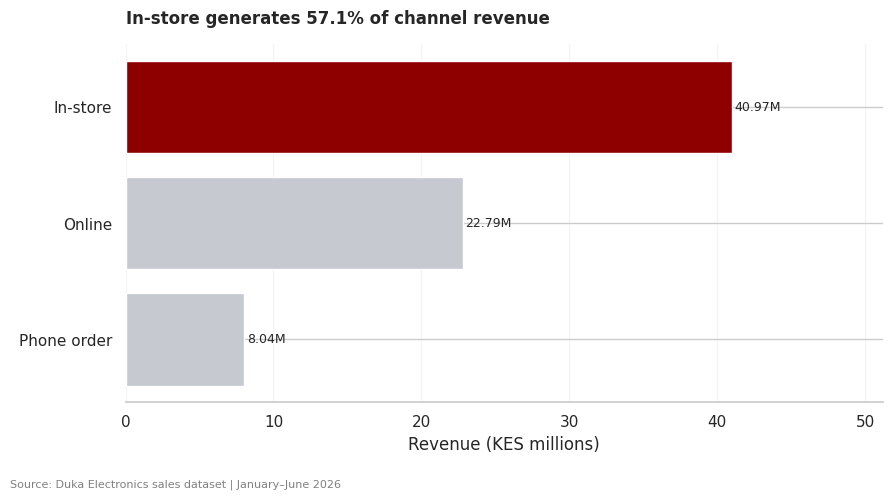

Top channel: In-store
Share of channel revenue: 57.1%


In [ ]:

# Sales channel comparison for the board report

import matplotlib.pyplot as plt

channel_revenue = (
    h1_sales.groupby("channel")["revenue"]
    .sum()
    .sort_values()
)

top_channel = channel_revenue.idxmax()
top_share = channel_revenue.max() / channel_revenue.sum() * 100

colors = [
    "#8E0000" if channel == top_channel else "#C7C9D1"
    for channel in channel_revenue.index
]

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.barh(
    channel_revenue.index,
    channel_revenue.values / 1_000_000,
    color=colors
)

for bar, value in zip(bars, channel_revenue.values):
    ax.text(
        bar.get_width() + 0.2,
        bar.get_y() + bar.get_height() / 2,
        f"{value / 1_000_000:.2f}M",
        va="center",
        fontsize=9
    )

ax.set_title(
    f"{top_channel} generates {top_share:.1f}% of channel revenue",
    loc="left",
    fontweight="bold",
    pad=15
)
ax.set_xlabel("Revenue (KES millions)")
ax.set_ylabel("")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)
ax.set_xlim(0, channel_revenue.max() / 1_000_000 * 1.25)

fig.text(
    0.01, 0.01,
    "Source: Duka Electronics sales dataset | January–June 2026",
    fontsize=8,
    color="grey"
)

plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.savefig("figures/channel_revenue.png", dpi=200, bbox_inches="tight")
plt.show()

print(f"Top channel: {top_channel}")
print(f"Share of channel revenue: {top_share:.1f}%")

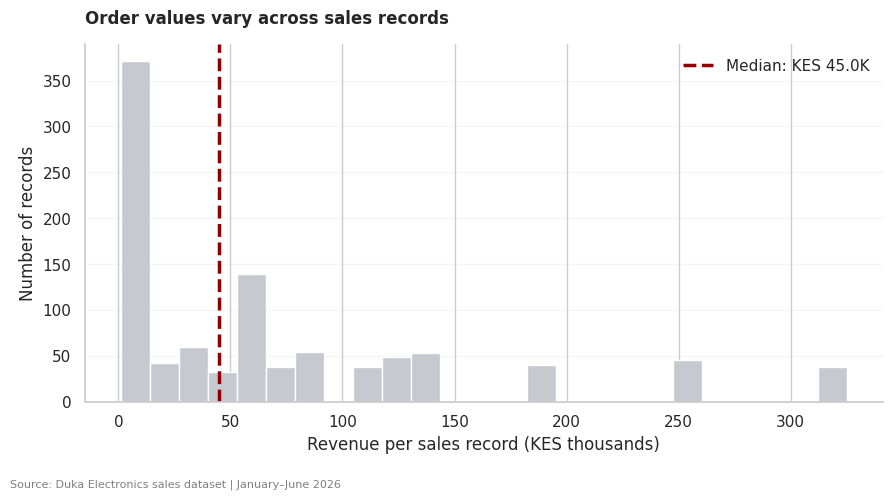

Median revenue per sales record: KES 45,000.00


In [ ]:

# Order revenue distribution for the board report

import matplotlib.pyplot as plt

order_revenue = h1_sales["revenue"].dropna() / 1000
median_revenue = order_revenue.median()

fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(
    order_revenue,
    bins=25,
    color="#C7C9D1",
    edgecolor="white"
)

ax.axvline(
    median_revenue,
    color="#8E0000",
    linewidth=2.5,
    linestyle="--",
    label=f"Median: KES {median_revenue:,.1f}K"
)

ax.set_title(
    "Order values vary across sales records",
    loc="left",
    fontweight="bold",
    pad=15
)
ax.set_xlabel("Revenue per sales record (KES thousands)")
ax.set_ylabel("Number of records")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
ax.legend(frameon=False)

fig.text(
    0.01, 0.01,
    "Source: Duka Electronics sales dataset | January–June 2026",
    fontsize=8,
    color="grey"
)

plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.savefig("figures/order_revenue_distribution.png", dpi=200, bbox_inches="tight")
plt.show()

print(f"Median revenue per sales record: KES {median_revenue * 1000:,.2f}")

In [ ]:

import os
from IPython.display import display, Image

os.makedirs("figures", exist_ok=True)

chart_files = [
    "product_revenue.png",
    "monthly_revenue.png",
    "branch_revenue.png",
    "channel_revenue.png",
    "order_revenue_distribution.png"
]

print("Checking saved charts...\n")

for filename in chart_files:
    filepath = os.path.join("figures", filename)
    if os.path.exists(filepath):
        print("FOUND:", filename)
    else:
        print("MISSING:", filename)

Checking saved charts...

FOUND: product_revenue.png
FOUND: monthly_revenue.png
FOUND: branch_revenue.png
FOUND: channel_revenue.png
FOUND: order_revenue_distribution.png


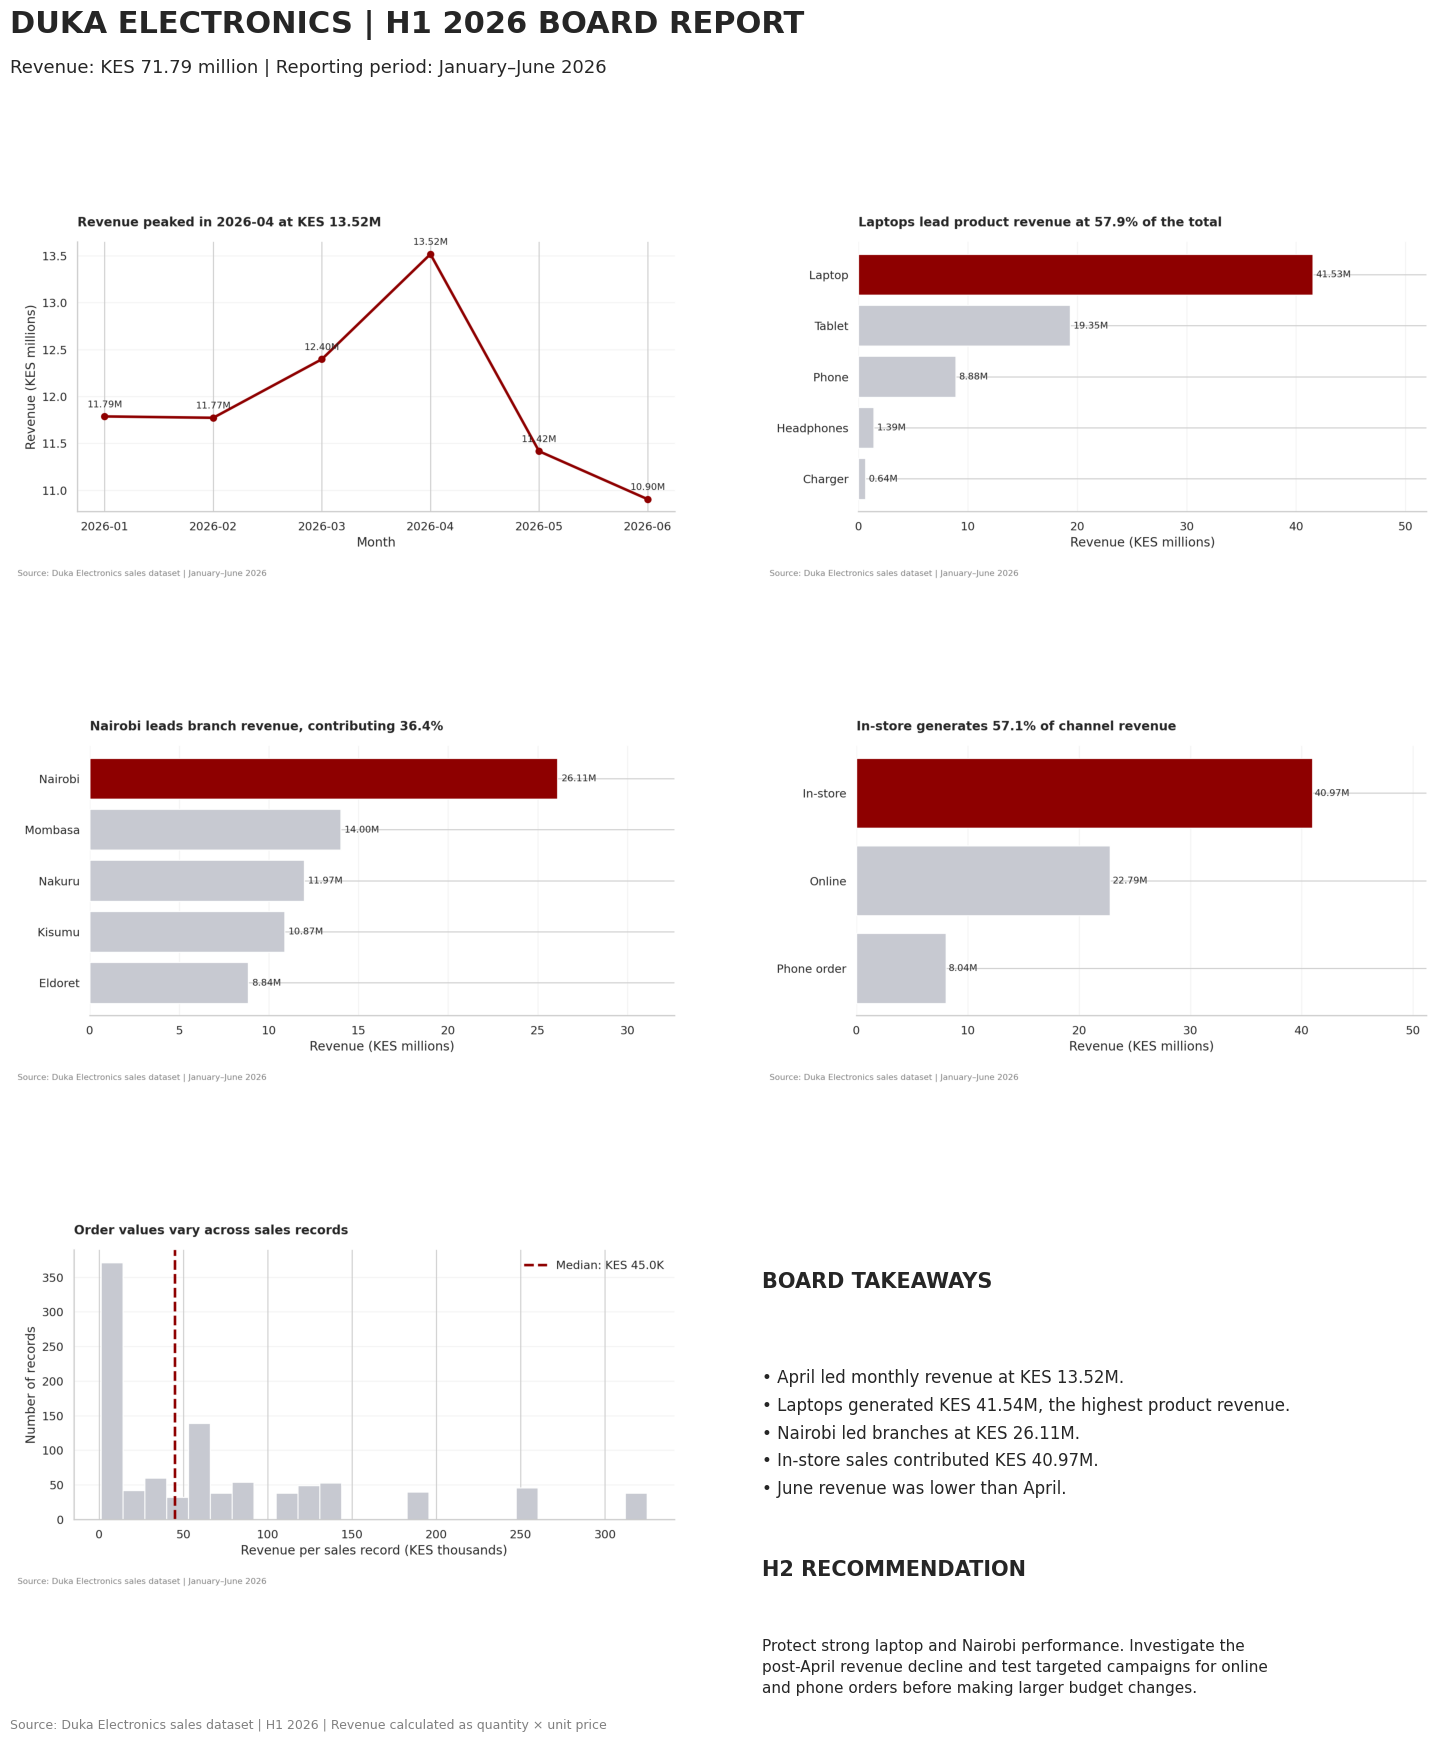

Saved: reports/duka_board_report.png


In [ ]:

import os
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

os.makedirs("reports", exist_ok=True)

fig = plt.figure(figsize=(16, 18))
fig.suptitle(
    "DUKA ELECTRONICS | H1 2026 BOARD REPORT",
    fontsize=22,
    fontweight="bold",
    x=0.06,
    ha="left",
    y=0.98
)

fig.text(
    0.06, 0.945,
    "Revenue: KES 71.79 million | Reporting period: January–June 2026",
    fontsize=13
)

chart_layout = [
    ("figures/monthly_revenue.png", [0.06, 0.64, 0.42, 0.25]),
    ("figures/product_revenue.png", [0.53, 0.64, 0.42, 0.25]),
    ("figures/branch_revenue.png", [0.06, 0.36, 0.42, 0.25]),
    ("figures/channel_revenue.png", [0.53, 0.36, 0.42, 0.25]),
    ("figures/order_revenue_distribution.png", [0.06, 0.08, 0.42, 0.25])
]

for filename, position in chart_layout:
    ax = fig.add_axes(position)
    image = mpimg.imread(filename)
    ax.imshow(image)
    ax.axis("off")

fig.text(
    0.53, 0.27,
    "BOARD TAKEAWAYS",
    fontsize=15,
    fontweight="bold"
)

fig.text(
    0.53, 0.225,
    "• April led monthly revenue at KES 13.52M.\n"
    "• Laptops generated KES 41.54M, the highest product revenue.\n"
    "• Nairobi led branches at KES 26.11M.\n"
    "• In-store sales contributed KES 40.97M.\n"
    "• June revenue was lower than April.",
    fontsize=12,
    linespacing=1.7,
    va="top"
)

fig.text(
    0.53, 0.11,
    "H2 RECOMMENDATION",
    fontsize=15,
    fontweight="bold"
)

fig.text(
    0.53, 0.075,
    "Protect strong laptop and Nairobi performance. Investigate the\n"
    "post-April revenue decline and test targeted campaigns for online\n"
    "and phone orders before making larger budget changes.",
    fontsize=11,
    linespacing=1.5,
    va="top"
)

fig.text(
    0.06, 0.025,
    "Source: Duka Electronics sales dataset | H1 2026 | Revenue calculated as quantity × unit price",
    fontsize=9,
    color="grey"
)

plt.savefig(
    "reports/duka_board_report.png",
    dpi=200,
    bbox_inches="tight",
    facecolor="white"
)
plt.show()

print("Saved: reports/duka_board_report.png")

SUCCESS: Board report image exists.
File size: 615.9 KB


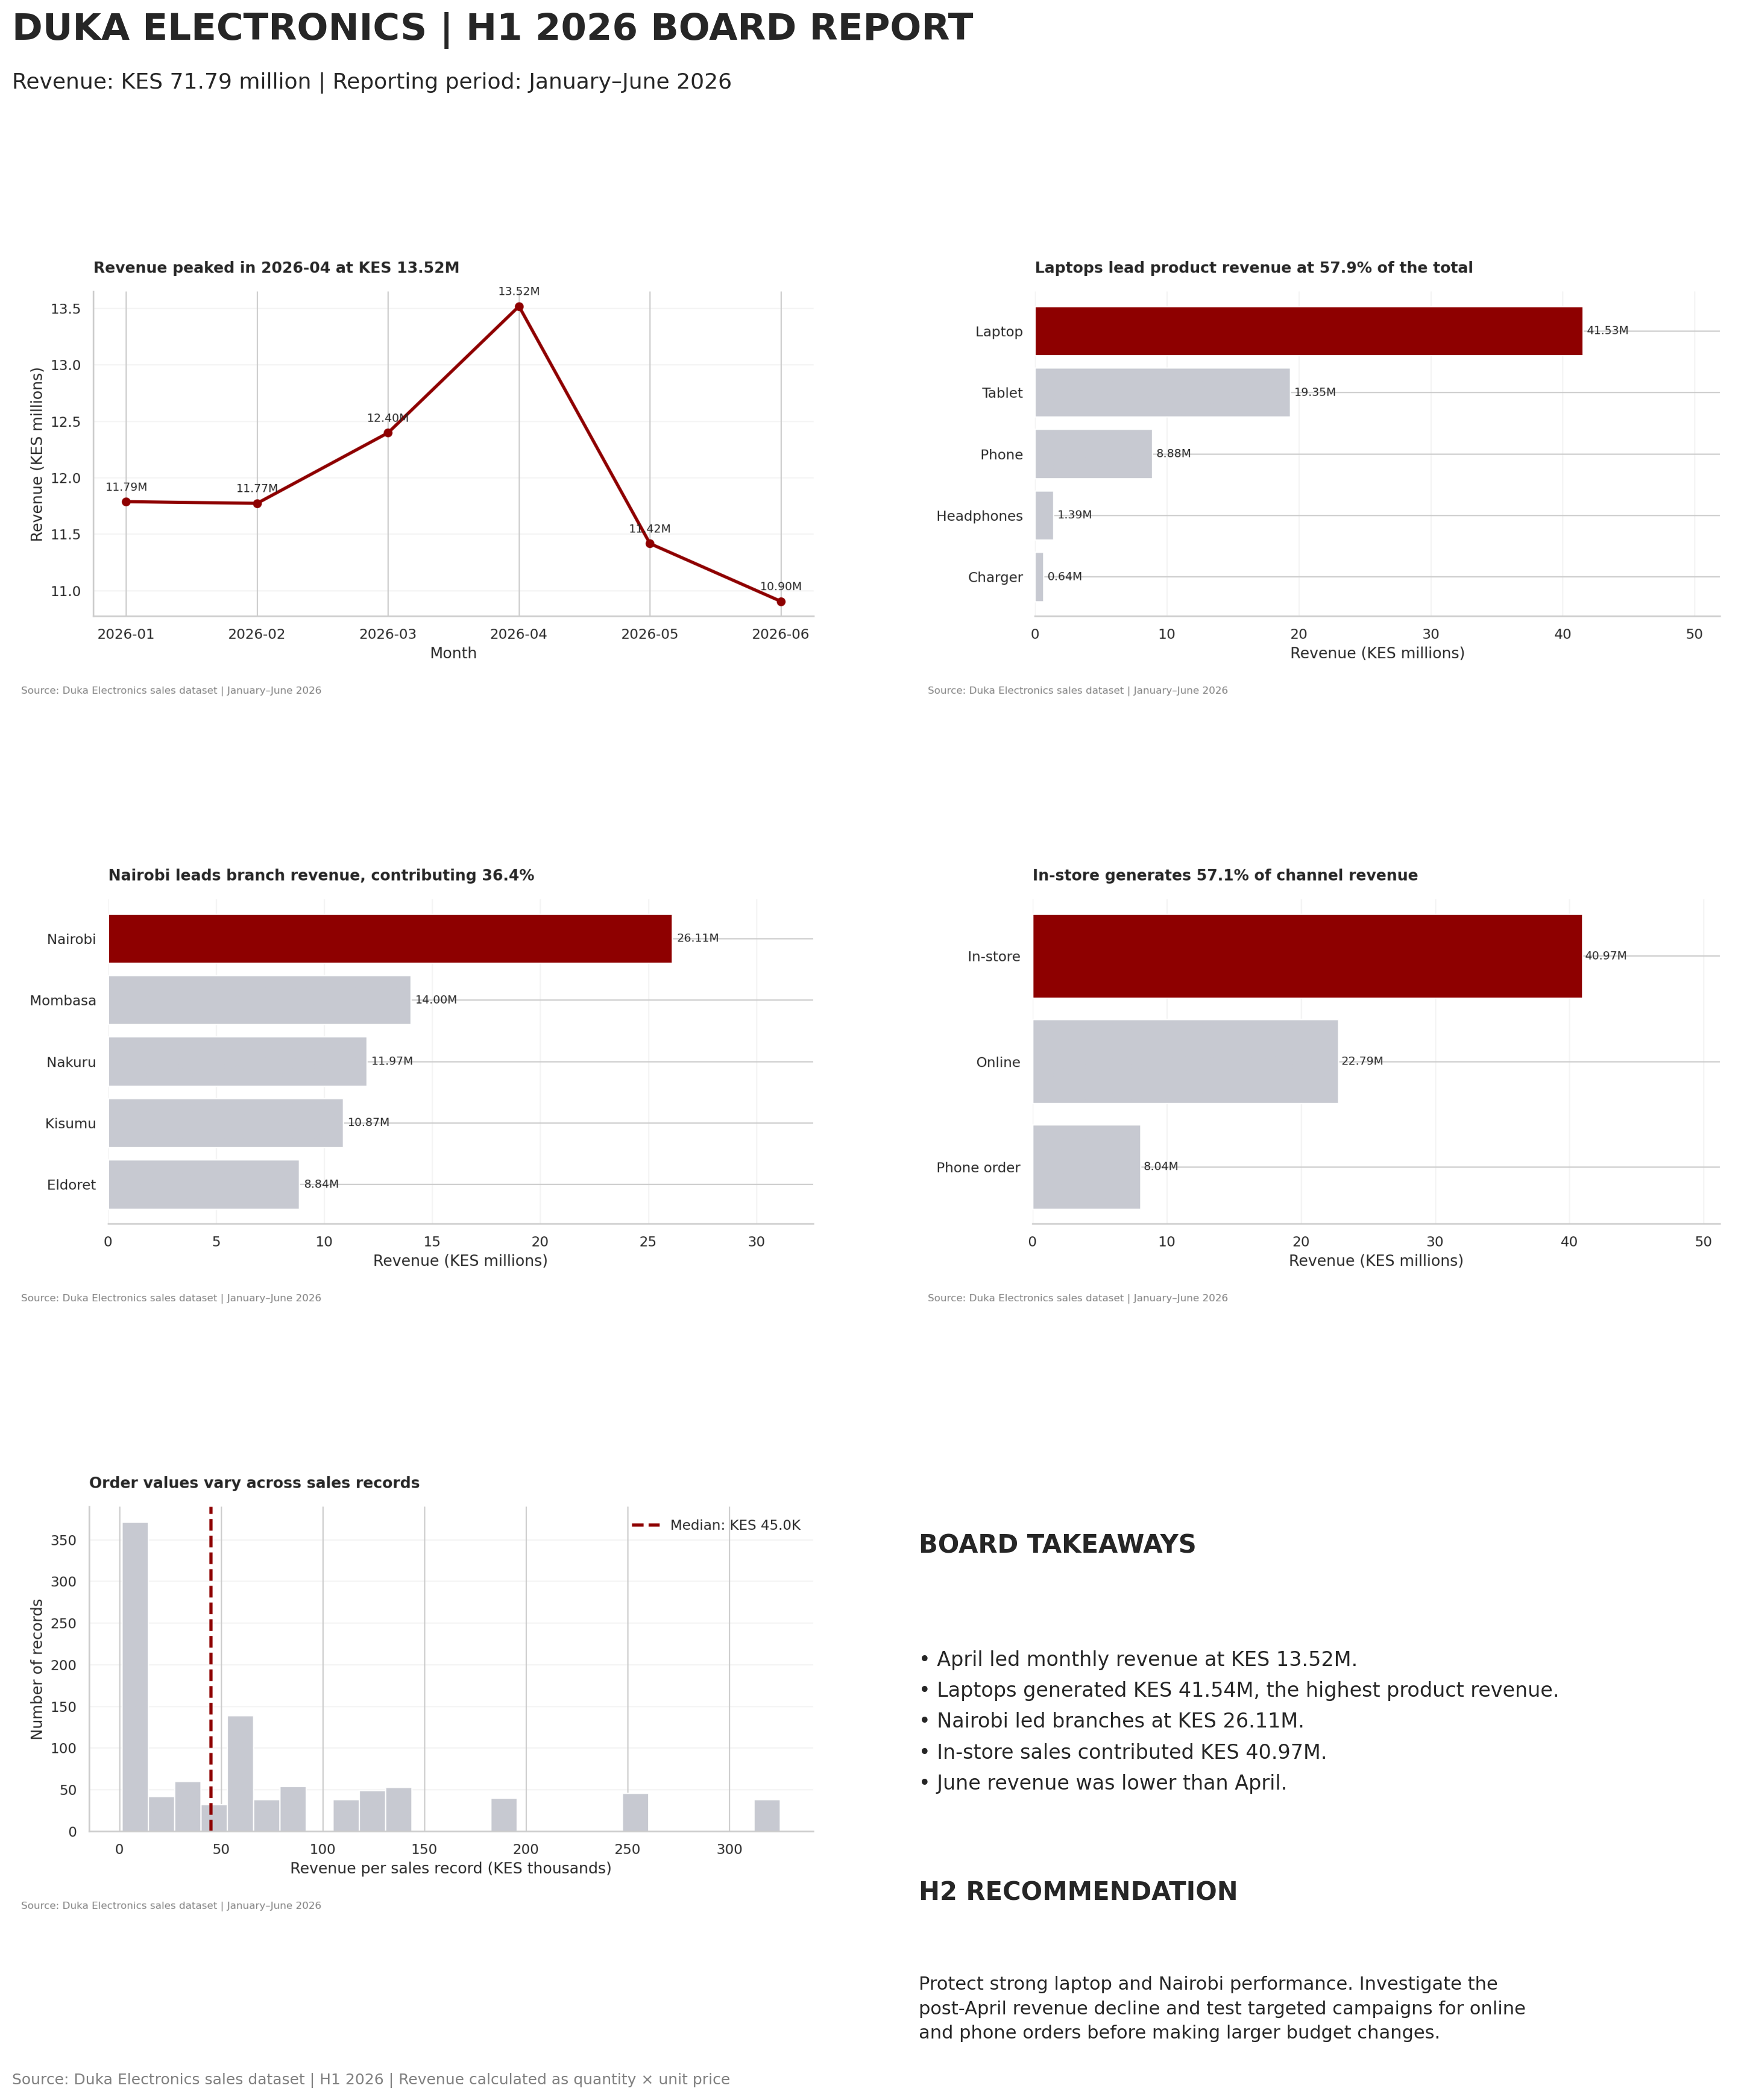

In [ ]:

import os
from IPython.display import display, Image

report_path = "reports/duka_board_report.png"

if os.path.exists(report_path):
    print("SUCCESS: Board report image exists.")
    print("File size:", round(os.path.getsize(report_path) / 1024, 1), "KB")
    display(Image(filename=report_path))
else:
    print("Report image not found. Please rerun Step 20.")

## Board Summary

Duka Electronics generated KES 71.79 million in revenue during H1 2026. April was the strongest month, contributing KES 13.52 million, while June recorded the lowest monthly revenue at KES 10.90 million. Laptops led product performance with KES 41.54 million, followed by tablets at KES 19.35 million. Nairobi was the highest-performing branch, generating KES 26.11 million, while Eldoret recorded KES 8.84 million. In-store sales contributed KES 40.97 million, compared with KES 22.79 million online and KES 8.04 million through phone orders.

For H2 2026, the board should protect the strong laptop category and review opportunities in Nairobi while investigating the decline in monthly revenue after April. Management should test targeted campaigns to grow online and phone-order sales, assess the causes of lower performance in Eldoret, and monitor results before committing additional budget. These actions should be evaluated using monthly revenue, branch performance, product mix, and channel contribution to guide evidence-based decisions.


In [ ]:

import os

required_files = [
    "reports/duka_board_report.png",
    "figures/before.png",
    "figures/after.png",
    "figures/product_revenue.png",
    "figures/monthly_revenue.png",
    "figures/branch_revenue.png",
    "figures/channel_revenue.png",
    "figures/order_revenue_distribution.png"
]

for filepath in required_files:
    if os.path.exists(filepath):
        print("FOUND:", filepath)
    else:
        print("MISSING:", filepath)

FOUND: reports/duka_board_report.png
FOUND: figures/before.png
FOUND: figures/after.png
FOUND: figures/product_revenue.png
FOUND: figures/monthly_revenue.png
FOUND: figures/branch_revenue.png
FOUND: figures/channel_revenue.png
FOUND: figures/order_revenue_distribution.png


In [ ]:

from google.colab import files

files.download("reports/duka_board_report.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

from google.colab import files

files.download("figures/before.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

files.download("figures/after.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>